In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
print("Libraries loaded successfully")

Libraries loaded successfully


Loading the dataset

In [2]:
df = pd.read_csv("../data/Palo_Alto_Networks.csv")
print(df.shape)
df.head()

(1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


Checking data quality

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.info()

Missing values: 0
Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   int64
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EnvironmentSatisfaction   1470 non-null   int64
 9   Gender                    1470 non-null   str  
 10  HourlyRate                1470 non-null   int64
 11  JobInvolvement            1470 non-null   int64
 12  JobLevel                  1470 non-null   int64
 13  JobRole                   1470 non-null   str  
 14  JobSatisfaction

Looking at the target column(attrition)

Attrition
0    1233
1     237
Name: count, dtype: int64

Attrition
0    0.839
1    0.161
Name: proportion, dtype: float64


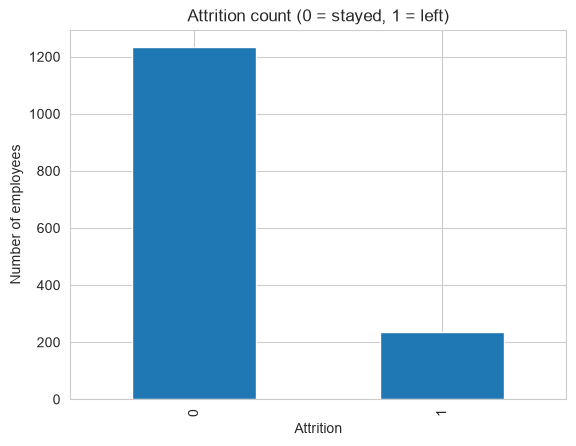

In [4]:
print(df["Attrition"].value_counts())
print()
print(df["Attrition"].value_counts(normalize=True).round(3))

df["Attrition"].value_counts().plot(kind="bar")
plt.title("Attrition count (0 = stayed, 1 = left)")
plt.xlabel("Attrition")
plt.ylabel("Number of employees")
plt.show()

Attrition by OverTime

OverTime
No     10.4
Yes    30.5
Name: Attrition, dtype: float64


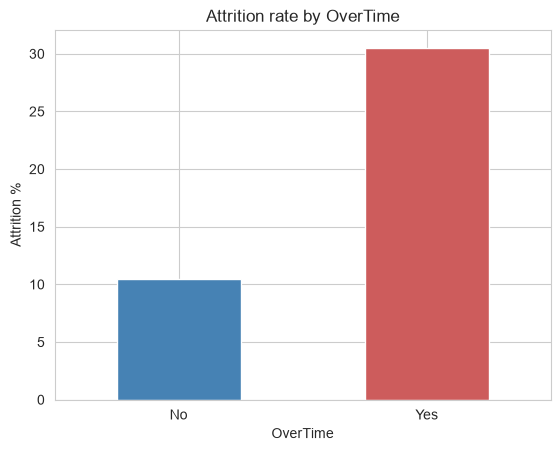

In [5]:
rate = df.groupby("OverTime")["Attrition"].mean() * 100
print(rate.round(1))

rate.plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Attrition rate by OverTime")
plt.ylabel("Attrition %")
plt.xticks(rotation=0)
plt.show()

Attrition by Job Role

JobRole
Research Director             2.5
Manager                       4.9
Healthcare Representative     6.9
Manufacturing Director        6.9
Research Scientist           16.1
Sales Executive              17.5
Human Resources              23.1
Laboratory Technician        23.9
Sales Representative         39.8
Name: Attrition, dtype: float64


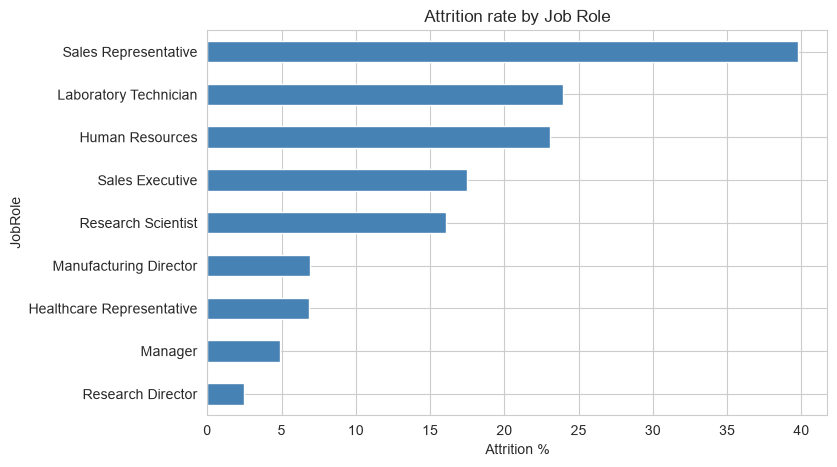

In [6]:
role_rate = df.groupby("JobRole")["Attrition"].mean().mul(100).sort_values()
print(role_rate.round(1))

role_rate.plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.title("Attrition rate by Job Role")
plt.xlabel("Attrition %")
plt.show()

Comparing income of people who left vs stayed

Attrition
0    5204.0
1    3202.0
Name: MonthlyIncome, dtype: float64


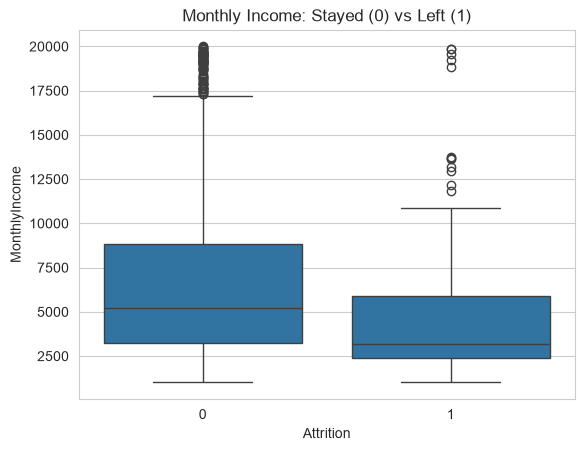

In [7]:
print(df.groupby("Attrition")["MonthlyIncome"].median())

sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")
plt.title("Monthly Income: Stayed (0) vs Left (1)")
plt.show()

Which numeric columns relate most to leaving?

TotalWorkingYears          -0.171
JobLevel                   -0.169
YearsInCurrentRole         -0.161
MonthlyIncome              -0.160
Age                        -0.159
YearsWithCurrManager       -0.156
StockOptionLevel           -0.137
YearsAtCompany             -0.134
JobInvolvement             -0.130
JobSatisfaction            -0.103
EnvironmentSatisfaction    -0.103
WorkLifeBalance            -0.064
TrainingTimesLastYear      -0.059
DailyRate                  -0.057
RelationshipSatisfaction   -0.046
YearsSinceLastPromotion    -0.033
Education                  -0.031
PercentSalaryHike          -0.013
HourlyRate                 -0.007
PerformanceRating           0.003
MonthlyRate                 0.015
NumCompaniesWorked          0.043
DistanceFromHome            0.078
Name: Attrition, dtype: float64


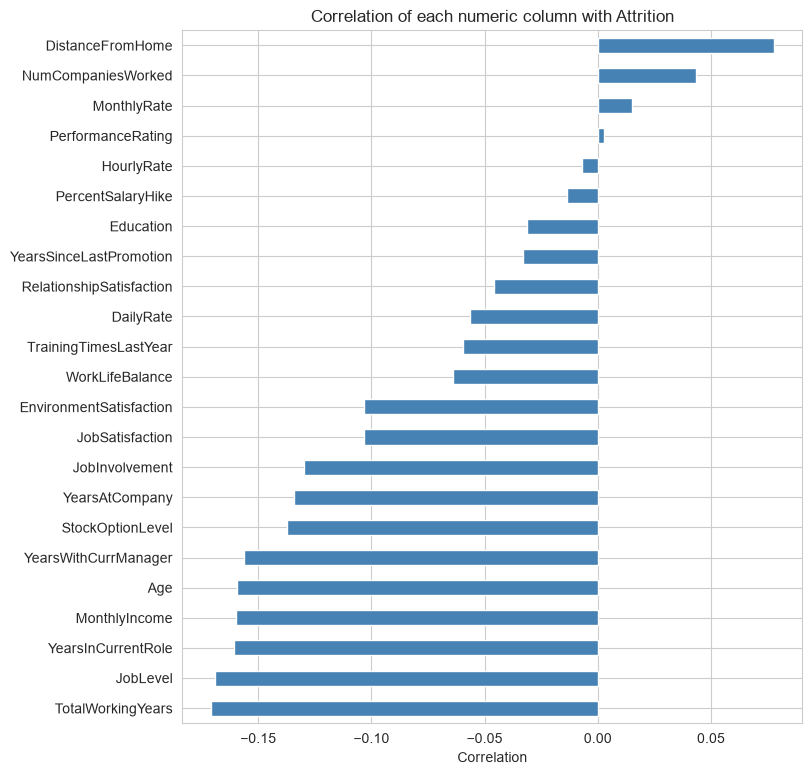

In [8]:
corr = df.corr(numeric_only=True)["Attrition"].drop("Attrition").sort_values()
print(corr.round(3))

corr.plot(kind="barh", figsize=(8, 9), color="steelblue")
plt.title("Correlation of each numeric column with Attrition")
plt.xlabel("Correlation")
plt.show()

Attrition by the text columns

In [9]:
for col in ["BusinessTravel", "MaritalStatus", "Department"]:
    print(df.groupby(col)["Attrition"].mean().mul(100).round(1))
    print()

BusinessTravel
Non-Travel            8.0
Travel_Frequently    24.9
Travel_Rarely        15.0
Name: Attrition, dtype: float64

MaritalStatus
Divorced    10.1
Married     12.5
Single      25.5
Name: Attrition, dtype: float64

Department
Human Resources           19.0
Research & Development    13.8
Sales                     20.6
Name: Attrition, dtype: float64

